In [141]:
import sys
import numpy as np
import pygame
import gymnasium as gym

from gymnasium.wrappers import RecordVideo
from gym_env.envs.grid_world import GridWorldEnv, Actions



In [142]:
def get_step_outcome(env, state, action):
    """Computes (next_state, reward, terminated) for a given (x, y) state and action."""
    pos = np.array(state, dtype=int)
    # Terminal states (target or bad cells) have 0 future transitions
    if (
        np.array_equal(pos, env._target_location)
        or np.array_equal(pos, env._bad1_location)
        or np.array_equal(pos, env._bad2_location)
    ):
        return tuple(pos), 0.0, True

    direction = env._action_to_direction[action]
    next_pos = np.clip(pos + direction, 0, env.size - 1)

    if np.array_equal(next_pos, env._target_location):
        return tuple(next_pos), 1.0, True
    elif np.array_equal(next_pos, env._bad1_location) or np.array_equal(next_pos, env._bad2_location):
        return tuple(next_pos), -1.0, True
    return tuple(next_pos), 0.0, False


def policy_iteration(env, gamma=0.9, theta=1e-6):
    policy = np.zeros((env.size, env.size), dtype=int)
    V = np.zeros((env.size, env.size), dtype=float)
    iterations = 0

    while True:
        iterations += 1
        # 1. Policy Evaluation
        while True:
            delta = 0.0
            for x in range(env.size):
                for y in range(env.size):
                    v_old = V[x, y]
                    (nx, ny), reward, terminated = get_step_outcome(env, (x, y), policy[x, y])
                    V[x, y] = reward + (0.0 if terminated else gamma * V[nx, ny])
                    delta = max(delta, abs(v_old - V[x, y]))
            if delta < theta:
                break

        # 2. Policy Improvement
        policy_stable = True
        for x in range(env.size):
            for y in range(env.size):
                old_action = policy[x, y]
                q_values = np.zeros(env.action_space.n)
                for a in range(env.action_space.n):
                    (nx, ny), reward, terminated = get_step_outcome(env, (x, y), a)
                    q_values[a] = reward + (0.0 if terminated else gamma * V[nx, ny])

                best_action = int(np.argmax(q_values))
                policy[x, y] = best_action
                if best_action != old_action and not np.isclose(q_values[best_action], q_values[old_action]):
                    policy_stable = False

        if policy_stable:
            break

    return policy, V, iterations

In [143]:
from gymnasium.wrappers import RecordVideo
seed_value = 42
env = GridWorldEnv(render_mode="rgb_array", size=5)
video_env = RecordVideo(
    env,
    video_folder="./videos",
    name_prefix=f"grid_maze_agent-{seed_value}",
    episode_trigger=lambda ep: True,
)

obs, info = video_env.reset(seed=seed_value)
policy, V, iters = policy_iteration(video_env.unwrapped, gamma=0.9)
print(f"Policy Iteration converged in {iters} iterations.")

terminated = False
steps = 0
while not terminated and steps < 50:
    agent_x, agent_y = obs["agent"]
    action = int(policy[agent_x, agent_y])
    obs, reward, terminated, truncated, info = video_env.step(action)
    steps += 1

video_env.close()
print(f"Episode finished in {steps} steps with final reward {reward}. Video saved to ./videos/")

Policy Iteration converged in 4 iterations.
Episode finished in 4 steps with final reward 1. Video saved to ./videos/


In [144]:
import numpy as np
import matplotlib.pyplot as plt

from collections import deque
from pathlib import Path
from IPython.display import Video, display

# Reconstruct the initial maze using the same seed.
# This does NOT run or record another episode.
reference_env = GridWorldEnv(render_mode=None, size=5)
initial_obs, _ = reference_env.reset(seed=seed_value)

start = tuple(initial_obs["agent"])
goal = tuple(initial_obs["target"])
bad_cells = {
    tuple(initial_obs["bad1"]),
    tuple(initial_obs["bad2"])
}

reference_env.close()
def format_position(position):
    return f"({int(position[0])}, {int(position[1])})"
print("Initial maze configuration:")
print(f"Agent: {format_position(start)}")
print(f"Goal: {format_position(goal)}")
print(f"Bad cells: {', '.join([format_position(cell) for cell in bad_cells])}")

Initial maze configuration:
Agent: (0, 3)
Goal: (3, 2)
Bad cells: (1, 0), (2, 4)


In [145]:
def bfs_shortest_path(start, goal, bad_cells, size):

    directions = {
        0: (1, 0),    # Right
        1: (0, -1),   # Up
        2: (-1, 0),   # Left
        3: (0, 1),    # Down
    }

    queue = deque([(start, [])])
    visited = {start}

    while queue:
        position, path = queue.popleft()

        if position == goal:
            return path

        x, y = position

        for action, (dx, dy) in directions.items():
            next_position = (
                np.clip(x + dx, 0, size - 1),
                np.clip(y + dy, 0, size - 1)
            )

            if next_position in bad_cells or next_position in visited:
                continue

            visited.add(next_position)
            queue.append((next_position, path + [action]))

    return None


optimal_path = bfs_shortest_path(
    start,
    goal,
    bad_cells,
    size=10
)

optimal_steps = len(optimal_path) if optimal_path is not None else None

actual_success = (
    terminated
    and tuple(obs["agent"]) == tuple(obs["target"])
)

if optimal_steps is not None:
    efficiency = (
        optimal_steps / steps * 100
        if actual_success and steps > 0
        else 0.0
    )

    print(f"Optimal BFS path length: {optimal_steps} steps")
    print(f"Actual agent path length: {steps} steps")
    print(f"Path efficiency: {efficiency:.2f}%")
else:
    efficiency = None
    print("No safe path to the goal exists.")

Optimal BFS path length: 4 steps
Actual agent path length: 4 steps
Path efficiency: 100.00%


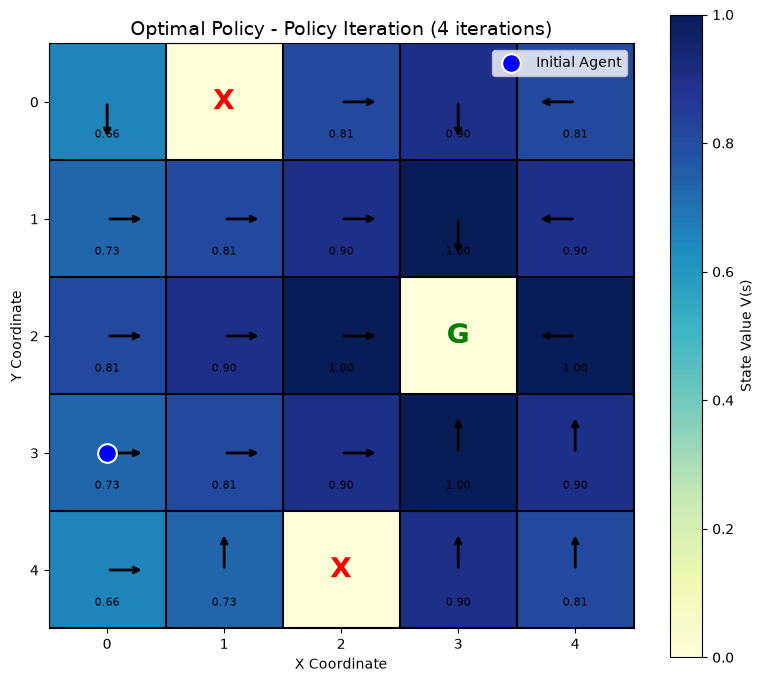

In [146]:
def plot_policy(policy, values, start, goal, bad_cells, size):

    fig, ax = plt.subplots(figsize=(8, 7))

    # State-value heatmap.
    image = ax.imshow(
        values.T,
        cmap="YlGnBu",
        origin="upper"
    )

    plt.colorbar(image, ax=ax, label="State Value V(s)")

    # Action directions: x increases right, y increases down.
    directions = {
        0: (1, 0),
        1: (0, -1),
        2: (-1, 0),
        3: (0, 1),
    }

    for x in range(size):
        for y in range(size):

            position = (x, y)

            if position == goal:
                ax.text(x, y, "G", ha="center", va="center",
                        fontsize=20, color="green", weight="bold")
                continue

            if position in bad_cells:
                ax.text(x, y, "X", ha="center", va="center",
                        fontsize=20, color="red", weight="bold")
                continue

            dx, dy = directions[int(policy[x, y])]

            ax.annotate(
                "",
                xy=(x + dx * 0.32, y + dy * 0.32),
                xytext=(x, y),
                arrowprops=dict(
                    arrowstyle="->",
                    color="black",
                    lw=2
                )
            )

            ax.text(
                x, y + 0.28,
                f"{values[x, y]:.2f}",
                ha="center",
                va="center",
                fontsize=8,
                color="black"
            )

    # Initial agent position.
    ax.scatter(
        start[0], start[1],
        color="blue",
        edgecolors="white",
        linewidths=1.5,
        s=180,
        label="Initial Agent",
        zorder=5
    )

    ax.set_xticks(range(size))
    ax.set_yticks(range(size))

    ax.set_xticks(np.arange(-0.5, size, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, size, 1), minor=True)

    ax.grid(which="minor", color="black", linewidth=1.5)
    ax.tick_params(which="minor", bottom=False, left=False)

    ax.set_title(
        f"Optimal Policy - Policy Iteration ({iters} iterations)",
        fontsize=14
    )

    ax.set_xlabel("X Coordinate")
    ax.set_ylabel("Y Coordinate")
    ax.legend(loc="upper right")

    plt.tight_layout()
    plt.show()


plot_policy(
    policy,
    V,
    start,
    goal,
    bad_cells,
    size=5
)

In [147]:
formatted_bad_cells = sorted(
    [format_position(cell) for cell in bad_cells]
)

print("=" * 48)
print("          GRID MAZE EXPERIMENT SUMMARY")
print("=" * 48)

print(f"{'Grid Size:':<24} 5 x 5")
print(f"{'Discount Factor:':<24} {0.9:.2f}")
print(f"{'Policy Iterations:':<24} {iters}")
print(f"{'Initial Position:':<24} {format_position(start)}")
print(f"{'Goal Position:':<24} {format_position(goal)}")
print(f"{'Bad Cells:':<24} {', '.join(formatted_bad_cells)}")

print("-" * 48)

print(f"{'Actual Steps:':<24} {steps}")
print(f"{'Optimal Steps (BFS):':<24} {optimal_steps}")
print(f"{'Path Efficiency:':<24} {efficiency:.2f}%")
print(f"{'Final Reward:':<24} {reward:.0f}")
print(f"{'Reached Goal:':<24} {'Yes' if actual_success else 'No'}")
print(f"{'Episode Terminated:':<24} {'Yes' if terminated else 'No'}")
print(f"{'Episode Truncated:':<24} {'Yes' if truncated else 'No'}")

print("=" * 48)

          GRID MAZE EXPERIMENT SUMMARY
Grid Size:               5 x 5
Discount Factor:         0.90
Policy Iterations:       4
Initial Position:        (0, 3)
Goal Position:           (3, 2)
Bad Cells:               (1, 0), (2, 4)
------------------------------------------------
Actual Steps:            4
Optimal Steps (BFS):     4
Path Efficiency:         100.00%
Final Reward:            1
Reached Goal:            Yes
Episode Terminated:      Yes
Episode Truncated:       No


In [148]:
video_files = sorted(
    Path("./videos").glob(f"grid_maze_agent-{seed_value}-episode-*.mp4"),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

if video_files:
    video_path = video_files[0]

    print(f"Playing: {video_path}")
    display(Video(str(video_path), embed=True, width=600))
else:
    print("No recorded video found. Check the ./videos directory.")

Playing: videos\grid_maze_agent-42-episode-0.mp4


QUESTIONS

Q1: What is the state-space size of the 5 × 5 Grid Maze problem?

Fixed Maze Instance : 25 states (5 × 5 possible agent positions).

Full Observation space:
Raw observation space: 5² × 5² × 5² × 5² = 25⁴ = 390,625 states.
Valid observations (no position overlap): 25 × 24 × 23 × 22 = 303,600 states (or 151,800 states if the two bad cells are treated as identical).

Q2: How to optimize Policy Iteration for the Grid Maze problem?

In-Place (Gauss-Seidel) Updates: Update value function values V(s) in-place during evaluation sweeps to accelerate convergence.

Truncated Policy Evaluation: Stop policy evaluation early after a sufficiently small threshold θ rather than waiting for full mathematical convergence.

Terminal State Skipping: Exclude terminal states (Target/Bad cells) from value update sweeps by keeping V(terminal) = 0.

Q3: How many iterations did it take to converge on a stable policy for the 5 × 5 maze?

Single Run (Seed 42): Converged in 4 iterations.

5-Episode Run (Seeds 100–104): Converged in 5 to 8 iterations (average: 6.4 iterations).

Episode | Seed | Convergence Iterations | Step Count | Total Reward
1       | 100  | 7                       | 5          | +1.0
2       | 101  | 5                       | 5          | +1.0
3       | 102  | 5                       | 2          | +1.0
4       | 103  | 8                       | 2          | +1.0
5       | 104  | 7                       | 3          | +1.0

Q4: Explain, with an example, how Policy Iteration behaves with multiple goal cells.

Policy Iteration evaluates paths to all goal cells simultaneously by propagating expected returns backward. There are two possible outcomes depending on whether the goals have equal or unequal rewards.

Equal Goal Rewards (Goal A = Goal B = +1.0):

The grid partitions based purely on shortest-path distance because the return decays by the number of steps (γ^d × 1.0). States automatically route toward the nearest goal.

Unequal Goal Rewards (Reward vs. Distance Trade-off):

Example: Goal A (distance d = 1) gives reward +1.0; Goal B (distance d = 4) gives reward +10.0.

Return to Goal A = 1.0.

Return to Goal B = 0.9³ × 10.0 = 7.29.

Behavior: The agent bypasses Goal A, even though it is nearby, to reach Goal B because 7.29 > 1.0.

Q5: Can Policy Iteration work on a 100 × 100 maze? Explain why?

Yes. A single grid layout has 100 × 100 = 10,000 states, the agent does not care where the bad states or goal is, which presents no memory issues.

Q6: Can Policy Iteration work on a continuous-space maze? Explain why?

No. Continuous spaces contain an uncountably infinite number of states (x, y) as real numbers, making finite lookup tables for V(s) and Pi(s) impossible, an alternative would be space discretization

Q7: Can Policy Iteration work with moving bad cells (like Pac-Man moving ghosts)? Explain why?

Standard Spatial State (x_a, y_a): No. Omitting ghost positions breaks the Markov Property, causing environmental transition dynamics to change unpredictably over time.

however we could include ghost positions, s = (x_a, y_a, x_g1, y_g1, x_g2, y_g2), and ghost transition probabilities are fully known.

But the state space grows dramatically (25^3 = 15,625 states for a 5 × 5 grid; 10^12 states for a 100 × 100 grid).